# Bài tập tại lớp

   DienTich          Gia
0       222  6831.619335
1        97  2995.581976
2       167  5436.324221
3       242  7735.730612
4       117  3336.843175
DienTich    0
Gia         0
dtype: int64
Hệ số chặn (Intercept): 196.70537860217337
Hệ số góc (Slope): [29.08798537]
Sai số bình phương trung bình (MSE): 106347.00141335213
R^2 score: 0.9765369589595868


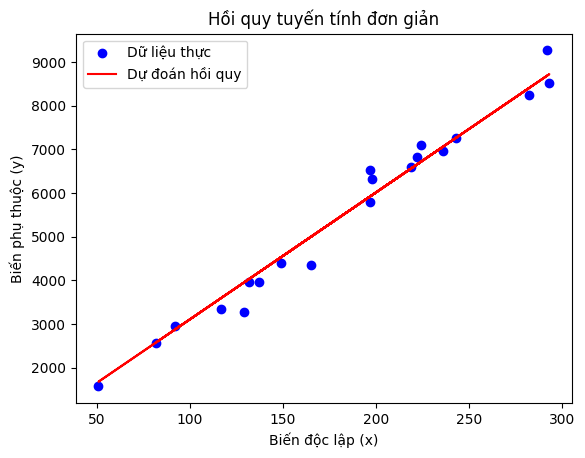

Số liệu b1.2
     n  noise          MSE       R2
    50    100       5564.9    0.997
    50    300      62861.2    0.964
    50   1000     499056.4    0.753
   500    100      11147.0    0.995
   500    300      84856.8    0.957
   500   1000    1036020.8    0.637
  5000    100       9780.2    0.996
  5000    300      89520.6    0.962
  5000   1000     935432.9    0.686
Số liệu b1.3
Hệ số chặn: 61.08144598011722
  DienTich: 30.27
  SoPhong: 82.93
  TuoiNha: -9.34
  KhoangCach: -27.30
MSE: 31651.111268010278
R2 : 0.9844403092206075


In [21]:
#Bài 1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(0)
#1. Cần xây dựng một mô hình hồi quy tuyến tính đơn giản để dự đoán Giá bán dựa trên Diện tích nhà.
n = 100
dien_tich = np.random.randint(50, 300, n)
gia = 50 + 30 * dien_tich + np.random.normal(0, 300, n)

df = pd.DataFrame({"DienTich": dien_tich, "Gia": gia})
print(df.head())
print(df.isnull().sum())

x = df[["DienTich"]]
y = df["Gia"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state = 42)

model = LinearRegression()

model.fit(x_train, y_train)

y_pred = model.predict(x_test)

mse = mean_squared_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print(f"Hệ số chặn (Intercept): {model.intercept_}")
print(f"Hệ số góc (Slope): {model.coef_}")
print(f"Sai số bình phương trung bình (MSE): {mse}")
print(f"R^2 score: {r2}")

plt.scatter(x_test, y_test, color="blue", label="Dữ liệu thực")
plt.plot(x_test, y_pred, color="red", label="Dự đoán hồi quy")
plt.title("Hồi quy tuyến tính đơn giản")
plt.xlabel("Biến độc lập (x)")
plt.ylabel("Biến phụ thuộc (y)")
plt.legend()
plt.show()

#2. Thêm nhiều (số lượng) dữ liệu và độ nhiễu để xem mô hình hoạt động như thế nào.
def chay_hoi_quy_don(n, noise):
    """Sinh dữ liệu với n mẫu, nhiễu = noise; huấn luyện và trả về (MSE, R2)."""
    x = np.random.uniform(30, 200, n).reshape(-1, 1)
    y = 50 + 30 * x.ravel() + np.random.normal(0, noise, n)
    xtr, xte, ytr, yte = train_test_split(x, y, test_size=0.2, random_state=42)
    m = LinearRegression().fit(xtr, ytr)
    yp = m.predict(xte)
    return mean_squared_error(yte, yp), r2_score(yte, yp)

np.random.seed(0)
print(f"Số liệu b1.2")
print(f"{'n':>6} {'noise':>6} {'MSE':>12} {'R2':>8}")
for n in [50, 500, 5000]:
    for noise in [100, 300, 1000]:
        mse, r2 = chay_hoi_quy_don(n, noise)
        print(f"{n:>6} {noise:>6} {mse:>12.1f} {r2:>8.3f}")

#3. Thêm các biến đầu vào khác để nâng cao tính phức tạp của mô hình.
n1 = 500
dien_tich = np.random.uniform(30, 200, n1)
so_phong  = np.random.randint(1, 6, n1)
tuoi_nha  = np.random.randint(0, 40, n1)
k_cach    = np.random.uniform(1, 20, n1)

gia = (100 + 30*dien_tich + 80*so_phong - 10*tuoi_nha - 25*k_cach
       + np.random.normal(0, 200, n1))

df2 = pd.DataFrame({"DienTich": dien_tich, "SoPhong": so_phong,
                    "TuoiNha": tuoi_nha, "KhoangCach": k_cach, "Gia": gia})
X = df2.drop(columns="Gia")
y = df2["Gia"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)
print(f"Số liệu b1.3")
print("Hệ số chặn:", model.intercept_)
for ten, he_so in zip(X.columns, model.coef_):
    print(f"  {ten}: {he_so:.2f}")
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 :", r2_score(y_test, y_pred))


5 mẫu đầu: BMI / xác suất / nhãn dự đoán / nhãn thật
   27.1  0.425  0  0
   28.4  0.552  1  0
   25.8  0.299  0  0
   29.1  0.616  1  0
   23.5  0.141  0  0
Accuracy: 0.7666666666666667
Ma trận nhầm lẫn:
 [[33  7]
 [ 7 13]]
              precision    recall  f1-score   support

           0       0.82      0.82      0.82        40
           1       0.65      0.65      0.65        20

    accuracy                           0.77        60
   macro avg       0.74      0.74      0.74        60
weighted avg       0.77      0.77      0.77        60



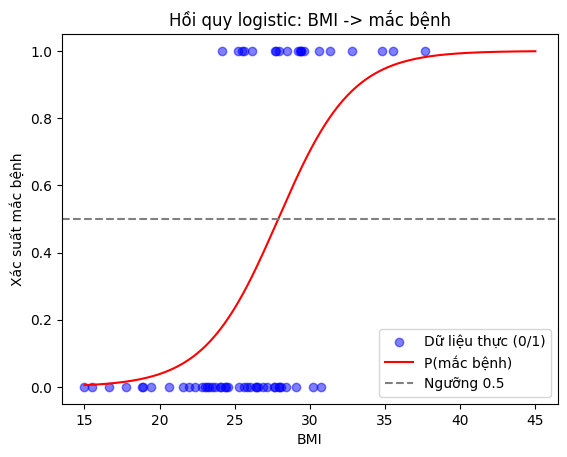

In [20]:
#Bài 2. Dự đoán khả năng mắc bệnh dựa trên chỉ số BMI
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, confusion_matrix,
                             classification_report, precision_score, recall_score)
# 1. Tạo dữ liệu giả lập: BMI càng cao thì xác suất mắc bệnh càng lớn
np.random.seed(1)
n = 300
bmi = np.random.normal(25, 5, n).clip(15, 45)
xac_suat_that = 1 / (1 + np.exp(-(bmi - 28) * 0.5))
mac_benh = (np.random.rand(n) < xac_suat_that).astype(int)
X = bmi.reshape(-1, 1)
y = mac_benh

# 2–3. Chia dữ liệu và huấn luyện Logistic Regression
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
log_model = LogisticRegression()
log_model.fit(X_train, y_train)

# 4. Dự đoán xác suất và nhãn
proba = log_model.predict_proba(X_test)[:, 1]
y_pred = log_model.predict(X_test)
print("5 mẫu đầu: BMI / xác suất / nhãn dự đoán / nhãn thật")
for b, p, yp, yt in list(zip(X_test.ravel(), proba, y_pred, y_test))[:5]:
    print(f"  {b:5.1f}  {p:.3f}  {yp}  {yt}")

# 5. Đánh giá
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Ma trận nhầm lẫn:\n", confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

X_test_bmi, y_test_bmi = X_test, y_test

# 6. Trực quan hóa dữ liệu và đường logistic
bmi_range = np.linspace(15, 45, 200).reshape(-1, 1)
plt.scatter(X_test, y_test, color="blue", alpha=0.5, label="Dữ liệu thực (0/1)")
plt.plot(bmi_range, log_model.predict_proba(bmi_range)[:, 1], color="red", label="P(mắc bệnh)")
plt.axhline(0.5, color="gray", linestyle="--", label="Ngưỡng 0.5")
plt.xlabel("BMI"); plt.ylabel("Xác suất mắc bệnh")
plt.title("Hồi quy logistic: BMI -> mắc bệnh"); plt.legend(); plt.show()

(442, 11)
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  
0 ô bị thiếu
                mean        std        min         max
age    -2.511817e-19   0.047619  -0.107226    0.110727
sex     1.230790e-17   0.047619  -0.044642    0.050680
bmi    -2.245564e-16   0.047619  -0.090275    0.170555
bp     -4.797570e-17   0.047619  -0.112399    0.132044

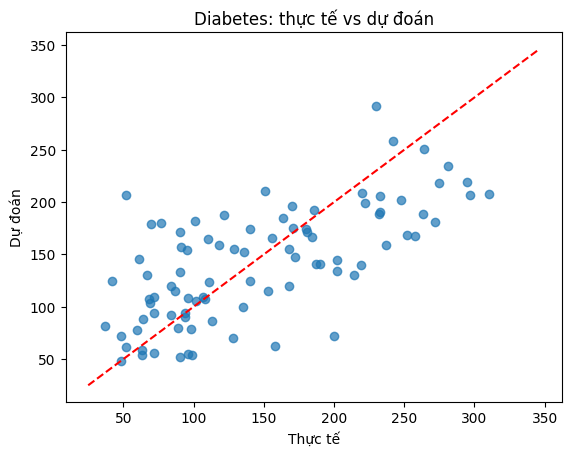

In [19]:
#Bài 3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, confusion_matrix,
                             classification_report, precision_score, recall_score)

from sklearn.datasets import load_diabetes

data = load_diabetes(as_frame=True)
df3 = data.frame
print(df3.shape)
print(df3.head())

print(df3.isnull().sum().sum(), "ô bị thiếu")
print(df3.describe().T[["mean", "std", "min", "max"]])
print(df3.corr()["target"].sort_values(ascending=False))

X = df3.drop(columns="target")
y = df3["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)

model = LinearRegression().fit(X_train_s, y_train)
y_pred = model.predict(X_test_s)

mse = mean_squared_error(y_test, y_pred)
print("MSE :", mse)
print("RMSE:", np.sqrt(mse))
print("MAE :", mean_absolute_error(y_test, y_pred))
print("R2  :", r2_score(y_test, y_pred))

plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--")
plt.xlabel("Thực tế"); plt.ylabel("Dự đoán"); plt.title("Diabetes: thực tế vs dự đoán"); plt.show()

# Bài tập về nhà

In [18]:
#Bài 1: Thay đổi điều kiện sinh dữ liệu, ví dụ tăng độ nhiễu để kiểm tra độ chính xác của mô hình.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, confusion_matrix,
                             classification_report, precision_score, recall_score)

np.random.seed(0)
x = 2 * np.random.rand(100, 1)
ket_qua = []
for noise in [0.1, 0.5, 1, 2, 4]:
    y = 4 + 3 * x + noise * np.random.randn(100, 1)   # noise = độ lệch chuẩn của nhiễu
    xtr, xte, ytr, yte = train_test_split(x, y, test_size=0.2, random_state=42)
    m = LinearRegression().fit(xtr, ytr)
    yp = m.predict(xte)
    ket_qua.append([noise, m.intercept_[0], m.coef_[0][0],
                    mean_squared_error(yte, yp), r2_score(yte, yp)])

print(pd.DataFrame(ket_qua, columns=["Nhiễu", "Intercept", "Slope", "MSE", "R2"]).round(3))

   Nhiễu  Intercept  Slope     MSE     R2
0    0.1      4.021  2.999   0.009  0.995
1    0.5      3.991  2.913   0.215  0.907
2    1.0      3.984  2.961   0.781  0.737
3    2.0      3.858  3.024   4.409  0.510
4    4.0      2.953  3.548  24.377 -0.023


In [17]:
#Bài 2. Đổi ngưỡng dự đoán xác suất (ví dụ 0.6, 0.7,... thay vì 0.5) và quan sát sự thay đổi trong kết quả dự đoán.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, confusion_matrix,
                             classification_report, precision_score, recall_score)

proba = log_model.predict_proba(X_test_bmi)[:, 1]

for nguong in [0.3, 0.5, 0.6, 0.7, 0.9]:
    y_pred_n = (proba >= nguong).astype(int)
    print(f"--- Ngưỡng {nguong} ---")
    print("Accuracy :", round(accuracy_score(y_test_bmi, y_pred_n), 3))
    print("Precision:", round(precision_score(y_test_bmi, y_pred_n, zero_division=0), 3))
    print("Recall   :", round(recall_score(y_test_bmi, y_pred_n), 3))
    print(confusion_matrix(y_test_bmi, y_pred_n))

--- Ngưỡng 0.3 ---
Accuracy : 0.683
Precision: 0.516
Recall   : 0.8
[[25 15]
 [ 4 16]]
--- Ngưỡng 0.5 ---
Accuracy : 0.767
Precision: 0.65
Recall   : 0.65
[[33  7]
 [ 7 13]]
--- Ngưỡng 0.6 ---
Accuracy : 0.8
Precision: 0.786
Recall   : 0.55
[[37  3]
 [ 9 11]]
--- Ngưỡng 0.7 ---
Accuracy : 0.733
Precision: 0.75
Recall   : 0.3
[[38  2]
 [14  6]]
--- Ngưỡng 0.9 ---
Accuracy : 0.717
Precision: 1.0
Recall   : 0.15
[[40  0]
 [17  3]]


In [16]:
#Bài 3. Hồi quy tuyến tính với tập dữ liệu giá nhà ở
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (mean_squared_error, r2_score)

from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)
df4 = housing.frame
print(df4.head())

X = df4.drop(columns="MedHouseVal")
y = df4["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)

print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 :", r2_score(y_test, y_pred))

print(pd.Series(model.coef_, index=X.columns).round(3))

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  
MSE: 0.5558915986952444
R2 : 0.5757877060324508
MedInc        0.449
HouseAge      0.010
AveRooms     -0.123
AveBedrms     0.783
Population   -0.000
AveOccup     -0.004
Latitude     -0.420
Longitude    -0.434
dtype: float64
